# Rank Sweep Report Analysis

Concise analysis from `rank_pipeline_report.xlsx`: run matrix, dense plots, matched significance, and final takeaways.

In [1]:
from pathlib import Path
import json
import math
import re
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# this is the path where all the outputs live
ROOT = next(
    path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "configs/pipeline").exists() and (path / "outputs/pipeline_runs").exists()
)

import sys
sys.path.insert(0, str(ROOT))
from pipeline_tools.reporting.significance import build_significance_results

PRIMARY_METRICS = {
    "Belebele": ("acc_norm", "higher"),
    "FLORES": ("bits_per_byte", "lower"),
    "SIB200": ("acc", "higher"),
    "Taxi1500": ("acc", "higher"),
}
BENCHMARKS = list(PRIMARY_METRICS)

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 180})


def open_report(path):
    xls = pd.ExcelFile(path)
    return xls, {name: pd.read_excel(path, sheet_name=name) for name in xls.sheet_names}


def sheet(sheets, prefix):
    matches = [name for name in sheets if name == prefix or name.startswith(prefix)]
    if not matches:
        raise KeyError(f"No sheet matching {prefix!r}; available={list(sheets)}")
    return sheets[matches[0]].copy()


def clean_bool(series):
    return series.astype(str).str.lower().isin(["true", "yes", "1"])


def normalize_raw(raw):
    raw = raw.copy()
    raw = raw[~clean_bool(raw.get("is_baseline", pd.Series(False, index=raw.index)))].copy()
    wanted = []
    for benchmark, (metric, better) in PRIMARY_METRICS.items():
        part = raw[(raw.benchmark.eq(benchmark)) & (raw.metric.eq(metric))].copy()
        part["better"] = better
        wanted.append(part)
    metrics = pd.concat(wanted, ignore_index=True)
    metrics["value"] = pd.to_numeric(metrics["value"], errors="coerce")
    metrics = metrics.dropna(subset=["value"])

    group_cols = ["benchmark", "task", "metric"]
    lo = metrics.groupby(group_cols)["value"].transform("min")
    hi = metrics.groupby(group_cols)["value"].transform("max")
    span = hi - lo
    higher = (metrics["value"] - lo) / span
    lower = (hi - metrics["value"]) / span
    metrics["normalized_score"] = np.where(metrics["better"].eq("lower"), lower, higher)
    metrics.loc[(~np.isfinite(span)) | span.eq(0), "normalized_score"] = 1.0
    return metrics


def run_scores(metrics, extra_cols):
    index_cols = ["run_id", "kind", *extra_cols]
    scores = (
        metrics.groupby(index_cols + ["benchmark"], dropna=False)["normalized_score"]
        .mean()
        .unstack("benchmark")
        .reindex(columns=BENCHMARKS)
    )
    scores["aggregate_score"] = scores[BENCHMARKS].mean(axis=1)
    return scores.reset_index().sort_values("aggregate_score", ascending=False)


def exact_scores(metrics, extra_cols):
    frame = metrics.copy()
    frame["exact_value"] = np.where(frame.benchmark.eq("FLORES"), 2 ** frame.value, frame.value)
    return (
        frame.groupby(["run_id", "kind", *extra_cols, "benchmark"], dropna=False)["exact_value"]
        .mean()
        .unstack("benchmark")
        .reindex(columns=BENCHMARKS)
        .reset_index()
    )


def status_style(value):
    value = str(value)
    if value in {"complete_clean", "selected", "done", "yes"}:
        return "background-color: #c6efce; color: #006100"
    if value in {"not_computed", "not planned", "missing"}:
        return "background-color: #eeeeee; color: #666666"
    if "probe" in value or "short" in value or "incomplete" in value:
        return "background-color: #f4cccc; color: #990000"
    return "background-color: #ffeb9c; color: #9c6500"


def friedman_rows(significance, prefix):
    rows = []
    for item in significance.get("friedman_results", []):
        row = {
            "group_label": item.get("group_label"),
            "n_units": item.get("n_units"),
            "n_algorithms": item.get("n_algorithms"),
            "p_fdr": item.get("p_fdr"),
            "kendalls_w": item.get("kendalls_w"),
            "best_level": str(item.get("best_rank_approach", "")).replace(prefix, ""),
            "best_avg_rank": item.get("best_avg_rank"),
            "unique_winner_fdr": item.get("unique_winner_fdr"),
        }
        rows.append(row)
    return pd.DataFrame(rows)


def pairwise_rows(significance, prefix):
    rows = []
    for item in significance.get("pairwise_results", []):
        row = dict(item)
        row["label_a"] = str(row.get("label_a", "")).replace(prefix, "")
        row["label_b"] = str(row.get("label_b", "")).replace(prefix, "")
        rows.append(row)
    return pd.DataFrame(rows)

REPORT = ROOT / "outputs/pipeline_runs/moe_study_rank_sweep_pipeline_report/rank_pipeline_report.xlsx"
xls, sheets = open_report(REPORT)
raw = sheet(sheets, "benchmark_raw")
source = sheet(sheets, "source_manifest")
audit = sheet(sheets, "audit_status")
rank_summary_sheet = sheet(sheets, "rank_selection_rank_summary")
moe_rank_summary_sheet = sheet(sheets, "rank_selection_moe_rank_summary")
print(REPORT)
print(xls.sheet_names)

/scratch/hpc-prf-merlin/joel/moe-study/outputs/pipeline_runs/moe_study_rank_sweep_pipeline_report/rank_pipeline_report.xlsx
['benchmark_compact', 'data_overview', 'run_configs', 'pipeline_profile', 'benchmark_raw', 'experiment_meta', 'source_manifest', 'audit_status', 'rank_selection_rank_summary', 'rank_selection_kind_rank_summar', 'rank_selection_moe_rank_summary', 'rank_selection_friedman_by_benc', 'rank_selection_friedman_pairwis']


## Run Matrix

Rows are method families; columns are total rank. Green cells are selected clean runs in the report.

In [2]:
RANKS = [2, 4, 8, 16, 32, 64, 128, 256, 512, 1024]
TOTAL_RANK_RE = re.compile(r"_tr(\d+)_")
RANK_RE = re.compile(r"_r(\d+)(?:_|$)")


def parse_total_rank(run_id):
    run_id = str(run_id)
    m = TOTAL_RANK_RE.search(run_id)
    if m:
        return int(m.group(1))
    m = RANK_RE.search(run_id)
    if m:
        return int(m.group(1))
    return np.nan

status_rows = pd.concat([source, audit], ignore_index=True, sort=False)
status_rows["total_rank"] = status_rows.run_id.map(parse_total_rank)
status_rows = status_rows[status_rows.total_rank.notna()].copy()
status_rows["matrix_status"] = np.where(clean_bool(status_rows.get("selected_for_main", pd.Series(False, index=status_rows.index))), "complete_clean", status_rows.status.fillna("missing"))
status_rank = {"complete_clean": 0, "probe_or_incomplete": 1, "short_probe_not_valid": 1, "not_computed": 2}
status_rows["priority"] = status_rows.matrix_status.map(status_rank).fillna(1)
status_rows = status_rows.sort_values("priority").drop_duplicates(["kind", "total_rank"], keep="first")
run_matrix = (
    status_rows.assign(total_rank=lambda df: df.total_rank.astype(int))
    .pivot_table(index="kind", columns="total_rank", values="matrix_status", aggfunc="first")
    .reindex(columns=RANKS)
    .fillna("not planned")
)
display(run_matrix.style.map(status_style))

total_rank,2,4,8,16,32,64,128,256,512,1024
kind,,,,,,,,,,
adamole,not planned,not planned,not planned,probe_or_incomplete,probe_or_incomplete,probe_or_incomplete,probe_or_incomplete,probe_or_incomplete,not planned,not planned
cola,complete_clean,complete_clean,complete_clean,complete_clean,complete_clean,complete_clean,complete_clean,complete_clean,not planned,not planned
hmora,not planned,not planned,not planned,complete_clean,complete_clean,complete_clean,complete_clean,complete_clean,complete_clean,complete_clean
hydralora,complete_clean,complete_clean,complete_clean,complete_clean,complete_clean,complete_clean,complete_clean,complete_clean,not planned,not planned
lora,complete_clean,complete_clean,complete_clean,complete_clean,complete_clean,complete_clean,complete_clean,complete_clean,complete_clean,complete_clean
moelora,not planned,not planned,not planned,complete_clean,complete_clean,complete_clean,complete_clean,complete_clean,complete_clean,not planned
mola,not planned,not planned,not planned,complete_clean,complete_clean,complete_clean,complete_clean,complete_clean,complete_clean,complete_clean
mtllora,complete_clean,complete_clean,complete_clean,complete_clean,complete_clean,complete_clean,complete_clean,complete_clean,not planned,not planned


### explanation:
hmora, moelora, adamoe_1 (here mola) and adamole are MoE lora configurations. They have 8 experts and each expert has a rank of at least two, therfore they begin from a total rank of 16

## Scores and Dense Views

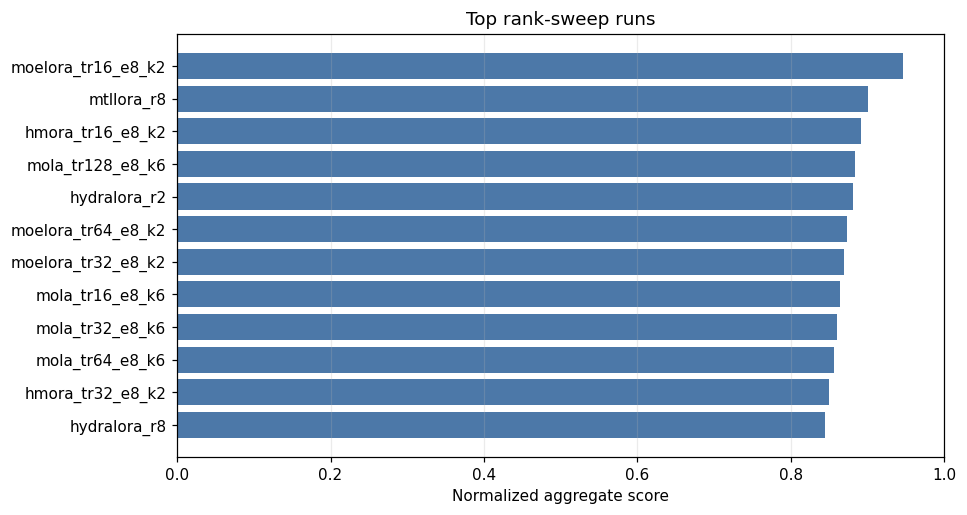

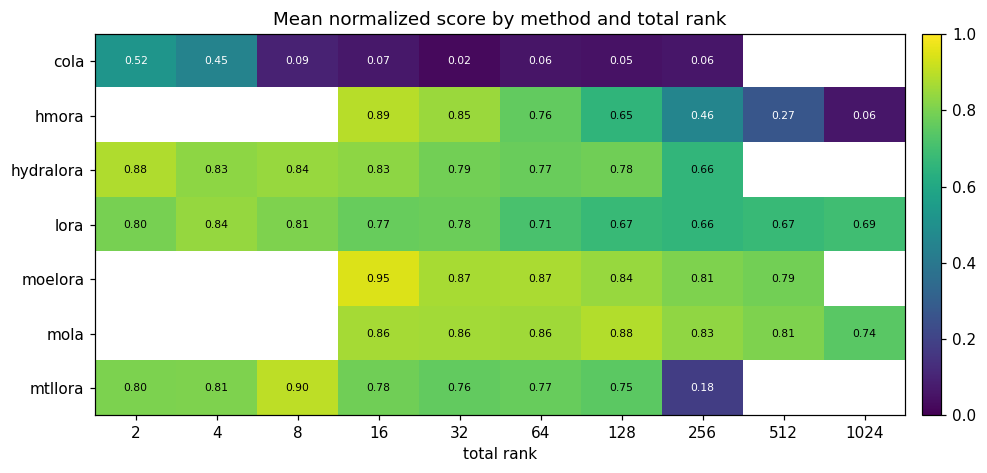

In [3]:
metrics = normalize_raw(raw)
metrics["total_rank"] = metrics.run_id.map(parse_total_rank)
metrics = metrics[metrics.total_rank.notna()].copy()
metrics["total_rank"] = metrics.total_rank.astype(int)
scores = run_scores(metrics, ["total_rank"])
exact = exact_scores(metrics, ["total_rank"])

fig, ax = plt.subplots(figsize=(9, 5))
top = scores.head(12).iloc[::-1]
ax.barh(top.run_id, top.aggregate_score, color="#4C78A8")
ax.set(xlabel="Normalized aggregate score", title="Top rank-sweep runs", xlim=(0, 1))
ax.grid(axis="x", alpha=0.25)
plt.show()

heat = scores.pivot_table(index="kind", columns="total_rank", values="aggregate_score", aggfunc="mean").reindex(columns=RANKS)
fig, ax = plt.subplots(figsize=(10, 4.5))
im = ax.imshow(heat, aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(len(heat.columns)), [str(c) for c in heat.columns])
ax.set_yticks(range(len(heat.index)), heat.index)
ax.set(title="Mean normalized score by method and total rank", xlabel="total rank")
for y, row in enumerate(heat.index):
    for x, col in enumerate(heat.columns):
        val = heat.loc[row, col]
        if pd.notna(val):
            ax.text(x, y, f"{val:.2f}", ha="center", va="center", fontsize=7, color="white" if val < 0.55 else "black")
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
plt.show()

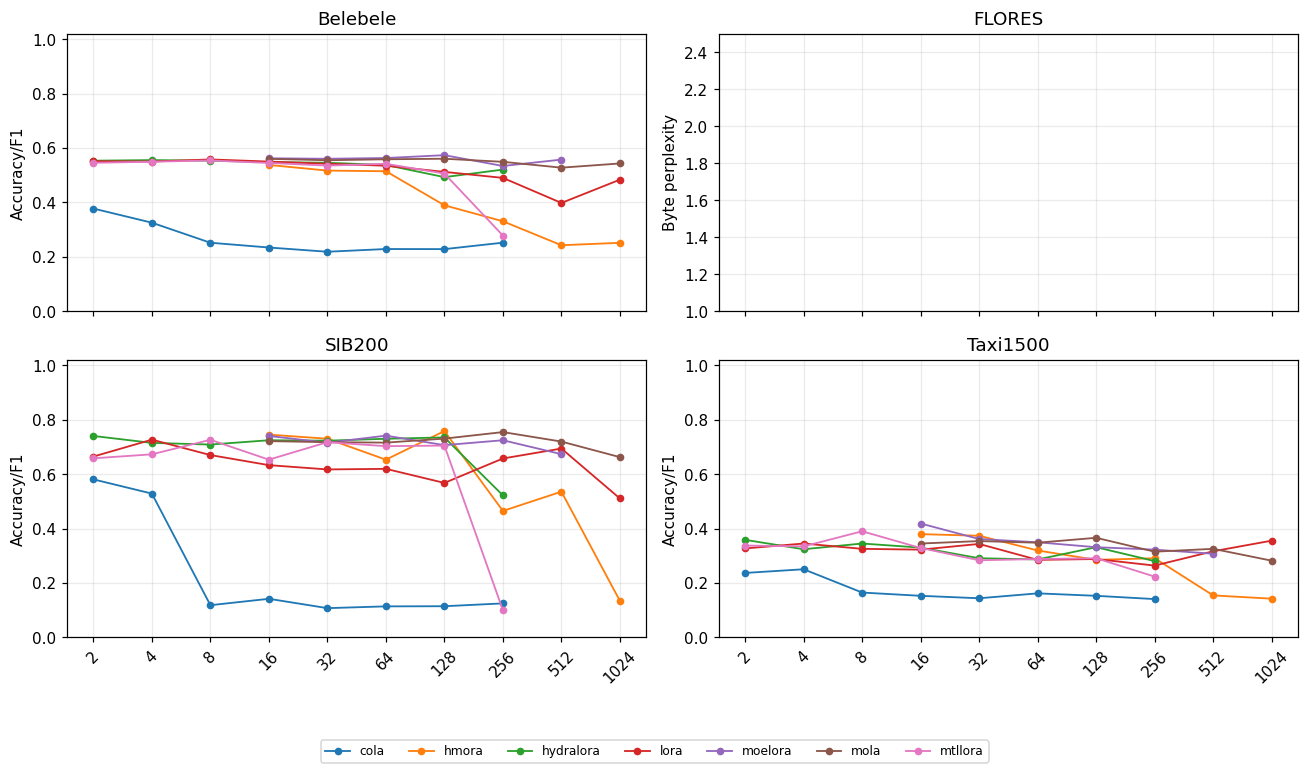

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
fields = [("Belebele", "Accuracy/F1"), ("FLORES", "Byte perplexity"), ("SIB200", "Accuracy/F1"), ("Taxi1500", "Accuracy/F1")]
for ax, (bench, ylabel) in zip(axes.flat, fields):
    for kind, group in exact.groupby("kind"):
        group = group.sort_values("total_rank")
        y = group[bench]
        if bench == "FLORES":
            y = y.clip(upper=2.5)
        ax.plot(group.total_rank, y, marker="o", linewidth=1.2, markersize=4, label=kind)
    ax.set_xscale("log", base=2)
    ax.set_xticks(RANKS)
    ax.set_xticklabels([str(r) for r in RANKS], rotation=45)
    ax.set_title(bench)
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)
    if bench == "FLORES":
        ax.set_ylim(1.0, 2.5)
    else:
        ax.set_ylim(0, 1.02)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=7, fontsize=8)
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

## Significance

Primary test: shared MoE total ranks across `moelora`, `mola`, and `hmora`. Exploratory tests run per method over that method's available ranks.

In [5]:
def rank_payload(frame, ranks, kinds):
    labels = [f"rank_{rank}" for rank in ranks]
    by_unit = defaultdict(dict)
    for row in frame.itertuples(index=False):
        if row.kind not in kinds or int(row.total_rank) not in ranks:
            continue
        key = (row.kind, row.benchmark, row.task, row.metric, row.better)
        by_unit[key][int(row.total_rank)] = row
    table_rows = []
    for (_kind, benchmark, task, metric, better), rank_rows in sorted(by_unit.items()):
        if all(rank in rank_rows for rank in ranks):
            table_rows.append({
                "benchmark": benchmark,
                "metric_family": metric,
                "task": task,
                "better": better,
                "approach_values": {f"rank_{rank}": float(rank_rows[rank].value) for rank in ranks},
            })
    return {"algorithm_labels": labels, "table_rows": table_rows}

shared_kinds = {"moelora", "mola", "hmora"}
shared_ranks = sorted(
    rank for rank in RANKS
    if metrics[metrics.kind.isin(shared_kinds) & metrics.total_rank.eq(rank)].run_id.nunique() == 3
)
rank_sig = build_significance_results(rank_payload(metrics, shared_ranks, shared_kinds))
rank_friedman = friedman_rows(rank_sig, "rank_")
rank_pairwise = pairwise_rows(rank_sig, "rank_")

per_method = []
for kind in sorted(metrics.kind.unique()):
    ranks = sorted(metrics.loc[metrics.kind.eq(kind), "total_rank"].unique())
    if len(ranks) < 3:
        continue
    sig = build_significance_results(rank_payload(metrics, ranks, {kind}))
    rows = friedman_rows(sig, "rank_")
    rows.insert(0, "kind", kind)
    per_method.append(rows)
per_method_friedman = pd.concat(per_method, ignore_index=True) if per_method else pd.DataFrame()

display(rank_friedman)
display(per_method_friedman[["kind", "group_label", "n_units", "p_fdr", "best_level", "unique_winner_fdr"]])

,group_label,n_units,n_algorithms,p_fdr,kendalls_w,best_level,best_avg_rank,unique_winner_fdr
0,Belebele,27,6,4.411344e-13,0.512935,16,2.259259,False
1,SIB200,27,6,7.793853e-05,0.194837,16,2.537037,False
2,Taxi1500,18,6,6.856824e-09,0.527367,16,2.055556,False


,kind,group_label,n_units,p_fdr,best_level,unique_winner_fdr
0,cola,Belebele,9,4.029578e-09,2,True
1,cola,SIB200,9,8.015744e-08,2,True
2,cola,Taxi1500,6,1.028864e-04,4,False
3,hmora,Belebele,9,9.083483e-09,16,True
4,hmora,SIB200,9,1.353608e-08,128,False
5,hmora,Taxi1500,6,5.137952e-05,32,False
6,hydralora,Belebele,9,4.368056e-07,4,False
7,hydralora,SIB200,9,1.312707e-06,2,False
8,hydralora,Taxi1500,6,6.978584e-05,2,False
9,lora,Belebele,9,1.525445e-08,8,False


## Takeaway

In [6]:
best_shared = moe_rank_summary_sheet.sort_values("mean_aggregate_score", ascending=False).iloc[0]
best_run = scores.iloc[0]
unique = rank_friedman[rank_friedman.unique_winner_fdr.eq(True)]
print(f"Best shared MoE total rank: {int(best_shared.total_rank)} (mean score={best_shared.mean_aggregate_score:.4f})")
print(f"Best single rank run: {best_run.run_id} (score={best_run.aggregate_score:.4f})")
print("Unique significant winners:", ", ".join(f"{r.group_label}: rank {r.best_level}" for r in unique.itertuples()) or "none")

Best shared MoE total rank: 16 (mean score=0.9286)
Best single rank run: moelora_tr16_e8_k2 (score=0.9460)
Unique significant winners: none
